**1. **Loading dataset and inspecting dataset****


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Mall_Customers.csv")

print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (200, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


**2. **Customer characteristics****

In [5]:
display(df.describe())

print("\nGender distribution:")
display(df["Gender"].value_counts())

print("\nAverage annual income:",
      round(df["Annual Income (k$)"].mean(), 2))

print("\nAverage spending score:",
      round(df["Spending Score (1-100)"].mean(), 2))


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Gender distribution:


Gender
Female    112
Male       88
Name: count, dtype: int64


Average annual income: 60.56

Average spending score: 50.2


**3. Distribution Chart**

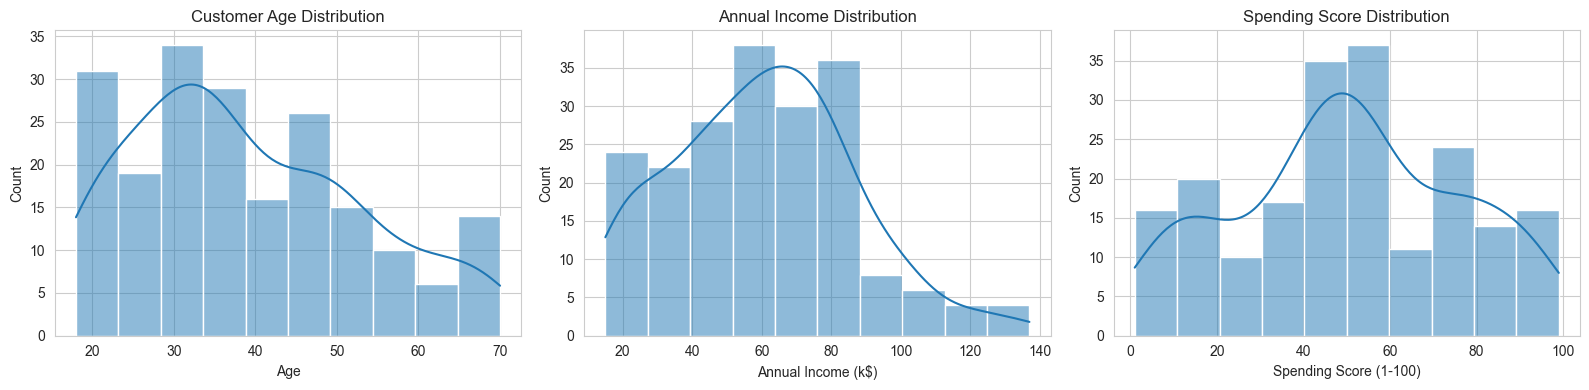

In [6]:
# Distribution of customer age, income, and spending score

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Age"], bins=10, kde=True, ax=axes[0])
axes[0].set_title("Customer Age Distribution")

sns.histplot(df["Annual Income (k$)"], bins=10, kde=True, ax=axes[1])
axes[1].set_title("Annual Income Distribution")

sns.histplot(df["Spending Score (1-100)"], bins=10, kde=True, ax=axes[2])
axes[2].set_title("Spending Score Distribution")

plt.tight_layout()
plt.show()

**3.1 Income vs. spending score**

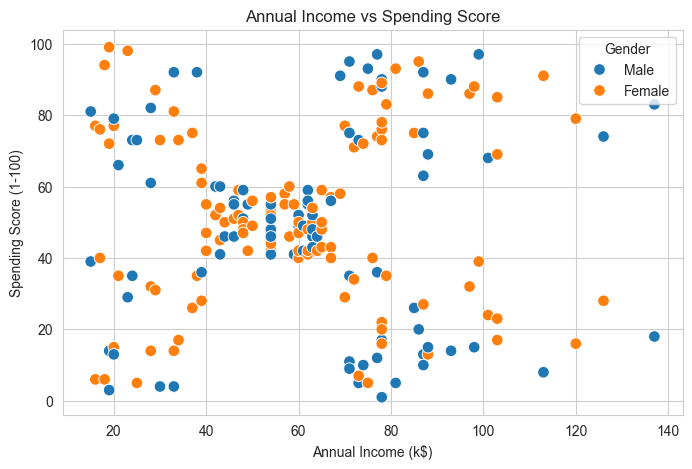

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=70
)

plt.title("Annual Income vs Spending Score")
plt.show()

**4. Select and standardize features**

In [9]:
from sklearn.preprocessing import StandardScaler

# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Standardized data shape:", X_scaled.shape)
print("\nFirst five standardized rows:")
display(pd.DataFrame(
    X_scaled,
    columns=["Annual Income (scaled)", "Spending Score (scaled)"]
).head())

Original data shape: (200, 2)
Standardized data shape: (200, 2)

First five standardized rows:


,Annual Income (scaled),Spending Score (scaled)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


**5. Elbow Method**

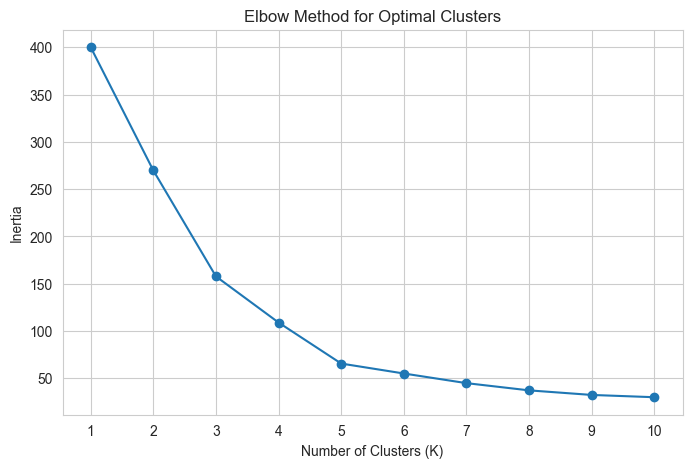

In [10]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**6. K-Means clustering**

In [12]:
# Applying K-Means with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer count in each cluster:")
display(df["Cluster"].value_counts().sort_index())

Customer count in each cluster:


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

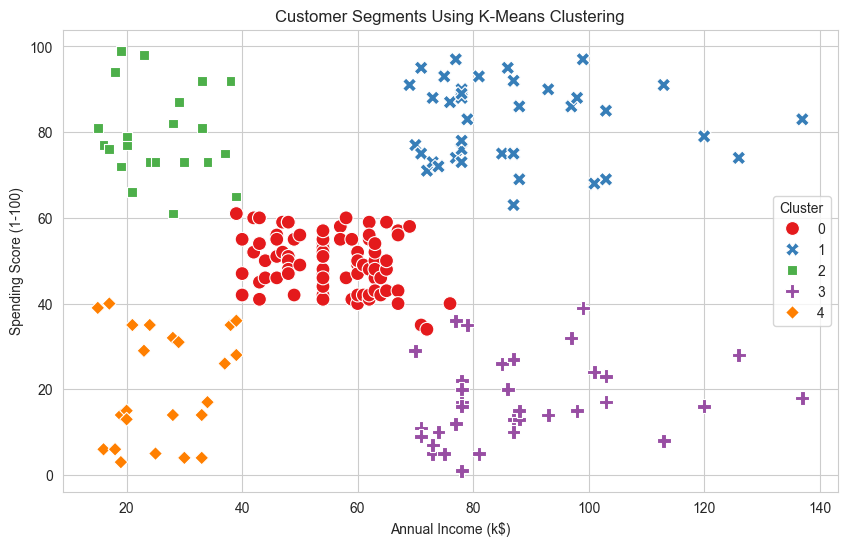

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100,
    style="Cluster"
)

plt.title("Customer Segments Using K-Means Clustering")
plt.legend(title="Cluster")
plt.show()

**7. Profile the customer segments**

In [14]:
# Summarize each customer segment
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

display(cluster_profile)

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


### **9. Marketing recommendations**

## Marketing Recommendations

1. **Cluster 0 – Average Customers:** Offer loyalty points, seasonal discounts, and product recommendations to encourage repeat purchases.

2. **Cluster 1 – Target High-Value Customers:** Provide premium product recommendations, exclusive offers, and personalized loyalty rewards.

3. **Cluster 2 – Young Enthusiastic Spenders:** Promote trending products, affordable premium items, and social-media campaigns.

4. **Cluster 3 – High-Income Low Spenders:** Use personalized promotions, product demonstrations, and exclusive offers to understand and encourage spending.

5. **Cluster 4 – Low-Income Low Spenders:** Offer budget-friendly products, value bundles, and occasional discounts.

### Conclusion

K-Means clustering identified five customer segments based on annual income and spending score. These segments help the business understand differences in customer spending behaviour and develop targeted marketing strategies. This can support better customer engagement and more effective promotional campaigns.